# 08 — Prophet | PharmaMed / PharmaDemand

**Objetivo:** avaliar Prophet como quarto candidato para o ensemble stacking de **LightGBM + XGBoost + SARIMAX → Ridge**. Compara previsão **D+15** sobre a mesma série ATC e o mesmo holdout dos demais modelos.

Este notebook usa `src/models/ProphetForecaster.py` (arquivo incluído no ZIP) e a estrutura de projeto do notebook `07_AutoTheta.ipynb`.

**Etapas:** 1. carregar dados; 2. checar datas/ATC; 3. GridSearch temporal; 4. recuperar somente observações reais de eventual lacuna; 5. avaliar D+15 estrito (para o stacking); 6. backtest D+1…D+15 (diagnóstico); 7. salvar tabelas, métricas e gráficos.

> **Sem vazamento:** a busca usa apenas `split=train`. Na avaliação D+15, para prever a data `t`, a classe é ajustada com dados observados até `t−15`. Os valores do holdout só entram no histórico de refits quando já pertencem ao passado daquela origem. Lacunas não são preenchidas artificialmente.

> **Limitação metodológica:** `model.gridSearchFind()` da classe atual seleciona parâmetros com blocos D+1…D+15, não exclusivamente no passo D+15. A avaliação D+15 abaixo é estrita, mas a otimização ainda é multi-horizonte. Confira isso antes de comparar sua metodologia final de stacking.

## 0. Preparação e dependências

No seu `.venv`, se necessário, execute **uma vez** no terminal:

```bash
python -m pip install prophet scikit-learn pandas numpy matplotlib pyarrow
```

Coloque `ProphetForecaster.py` em `src/models/` (ao lado das outras classes) antes de executar o notebook. Este notebook deve ser aberto dentro da pasta do projeto PharmaMed (por exemplo, `notebooks/08_Prophet.ipynb`).

In [1]:
from pathlib import Path
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Aceita execução da raiz ou dentro de notebooks/.
_here = Path.cwd().resolve()
ROOT = next((p for p in [_here, *_here.parents] if (p / "src").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Não encontrei a pasta src. Abra o notebook no projeto PharmaMed.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

try:
    from prophet import Prophet  # verifica instalação no ambiente do kernel
except ImportError as exc:
    raise ImportError("Instale a biblioteca no mesmo kernel: %pip install prophet") from exc

try:
    from src.models.ProphetForecaster import ProphetForecaster
except ImportError as exc:
    raise ImportError("Adicione ProphetForecaster.py em src/models/ do PharmaMed.") from exc

from src.config.config import MODELS_BASELINE
from src.repository.parquet_repository import ParquetRepository

print("Projeto:", ROOT)
print("Modelos:", MODELS_BASELINE)

Importing plotly failed. Interactive plots will not work.


Projeto: D:\PROJETOS\git_repo\PharmaDemand-ml
Modelos: D:\PROJETOS\git_repo\PharmaDemand-ml\models\baseline


## 1. Configuração e leitura do Parquet

A configuração abaixo segue seu notebook AutoTheta: `target_col="quantity"`, coluna `date`, horizonte 15 e arquivo `features/anomaly_predictions.parquet`.

**Categoria ATC:** se esse Parquet contiver várias categorias, configure `ATC_COL` e `ATC_VALUE` *antes de executar*. Com `series_col=None`, só pode existir **um registro por dia** no conjunto filtrado. Não agregue categorias inadvertidamente.

In [2]:
DATE = "date"
TARGET = "quantity"
HORIZON = 15   # Troque para 7 para fazer uma experiência distinta D+7.
N_SPLITS = 3
SCORING = "neg_root_mean_squared_error"

ATC_COL = None      # Exemplo: "ATC"; deixe None quando df já for de uma categoria.
ATC_VALUE = None    # Exemplo: "N02BE" quando ATC_COL estiver definido.

# Refazer o ajuste para cada data-alvo (1 = D+15 em TODOS os dias do teste).
# Valores maiores aceleram a exploração, mas avaliam menos datas.
FIXED_H_EVAL_STRIDE = 1

repo = ParquetRepository(base_path=ROOT / "data")
df_all = repo.load("features/anomaly_predictions.parquet").copy()

if ATC_COL is not None:
    if ATC_COL not in df_all.columns or ATC_VALUE is None:
        raise ValueError("Defina ATC_COL existente e ATC_VALUE antes de filtrar.")
    df_all = df_all.loc[df_all[ATC_COL].astype(str).eq(str(ATC_VALUE))].copy()

need = {DATE, TARGET, "split", "horizon_days"}
missing_cols = need - set(df_all.columns)
if missing_cols:
    raise ValueError(f"Colunas não encontradas no Parquet: {missing_cols}")

df_all[DATE] = pd.to_datetime(df_all[DATE], errors="raise").dt.normalize()
df_all[TARGET] = pd.to_numeric(df_all[TARGET], errors="raise")
df_h = df_all.loc[df_all["horizon_days"].eq(HORIZON)].copy()

train_daily = df_h.loc[df_h["split"].eq("train"), [DATE, TARGET]].copy().sort_values(DATE).reset_index(drop=True)
test_daily = df_h.loc[df_h["split"].eq("test"), [DATE, TARGET]].copy().sort_values(DATE).reset_index(drop=True)

for label, part in [("treino", train_daily), ("teste", test_daily)]:
    if part.empty:
        raise ValueError(f"Split {label} ficou vazio após filtro horizon_days={HORIZON}.")
    if part[DATE].isna().any() or part[TARGET].isna().any() or not np.isfinite(part[TARGET]).all():
        raise ValueError(f"O split {label} possui datas ou vendas nulas/inválidas.")
    if part[DATE].duplicated().any():
        examples = part.loc[part[DATE].duplicated(False), DATE].head(3).dt.date.tolist()
        raise ValueError(f"Datas repetidas em {label} ({examples}). Filtre uma categoria ATC em ATC_COL/ATC_VALUE.")

if train_daily[DATE].max() >= test_daily[DATE].min():
    raise ValueError("Treino e teste não podem ter datas sobrepostas.")

print("Treino:", len(train_daily), "|", train_daily[DATE].min().date(), "a", train_daily[DATE].max().date())
print("Teste:", len(test_daily), "|", test_daily[DATE].min().date(), "a", test_daily[DATE].max().date())
display(train_daily.head(3), test_daily.head(3))

[OK] Arquivo carregado: D:\PROJETOS\git_repo\PharmaDemand-ml\data\features\anomaly_predictions.parquet
Treino: 1852 | 2014-03-14 a 2019-04-08
Teste: 183 | 2019-04-09 a 2019-10-08


,date,quantity
0,2014-03-14,16.0
1,2014-03-15,23.3
2,2014-03-16,13.0


,date,quantity
0,2019-04-09,12.0
1,2019-04-10,34.0
2,2019-04-11,15.9


## 2. Conferência de frequência diária e intervalo treino → teste

Na execução anterior do AutoTheta, existia uma lacuna de sete datas entre o fim do treino e o início do teste. **Não use** `fillna(0)`, interpolação ou forward-fill para inventar `quantity`.

O notebook só tenta recuperar os dias ausentes a partir dos **valores efetivamente observados** no Parquet completo. Se não estiverem disponíveis, use sua fonte `df_salesdaily` filtrada na mesma ATC; caso contrário o código interrompe a avaliação.

In [3]:
def missing_dates(frame, date_col=DATE):
    days = pd.DatetimeIndex(frame[date_col]).sort_values()
    if days.has_duplicates:
        raise ValueError("Datas duplicadas na série diária.")
    return pd.date_range(days.min(), days.max(), freq="D").difference(days)

missing_train = missing_dates(train_daily)
missing_test = missing_dates(test_daily)
last_train = train_daily[DATE].max()
first_test = test_daily[DATE].min()
bridge_dates = pd.date_range(last_train + pd.Timedelta(days=1),
                             first_test - pd.Timedelta(days=1), freq="D")
print("Datas internas ausentes no treino:", len(missing_train))
print("Datas internas ausentes no teste:", len(missing_test))
print("Lacuna treino/teste:", len(bridge_dates), "dia(s)")
print("Exemplo:", list(bridge_dates[:7].date))

if len(missing_train) or len(missing_test):
    raise ValueError("O treino/teste tem lacunas INTERNAS. Corrija a fonte diária antes de continuar.")

Datas internas ausentes no treino: 0
Datas internas ausentes no teste: 0
Lacuna treino/teste: 0 dia(s)
Exemplo: []


C:\Users\AlexK\AppData\Local\Temp\ipykernel_10520\2197997044.py:11: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  bridge_dates = pd.date_range(last_train + pd.Timedelta(days=1),
C:\Users\AlexK\AppData\Local\Temp\ipykernel_10520\2197997044.py:12: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  first_test - pd.Timedelta(days=1), freq="D")


## 3. GridSearchCV temporal — **somente treino**

Grid de **12 combinações**, conforme discutimos. A classe já usa expanding-window por data e `n_jobs=1` para evitar concorrência pesada entre várias instâncias do Prophet.

A busca avalia **blocos inteiros** de 15 dias e, por isso, seu RMSE de CV não é diretamente o RMSE apenas do D+15. O holdout será avaliado de maneira estrita em outra etapa.

In [4]:
param_grid = {
    "model__changepoint_prior_scale": [0.01, 0.05, 0.1],
    "model__seasonality_prior_scale": [1.0, 5.0],
    "model__seasonality_mode": ["additive", "multiplicative"],
}

model = ProphetForecaster(
    target_col=TARGET,
    model_dir=MODELS_BASELINE,
    date_col=DATE,
    series_col=None,
    forecast_horizon=HORIZON,
    n_splits=N_SPLITS,
    scoring=SCORING,
    clip_nonnegative=True,
)

search = model.gridSearchFind(train_daily, param_grid=param_grid)
print("Melhores parâmetros:", search.best_params_)
print("RMSE médio CV (D+1..D+15):", -float(search.best_score_))

cv_results = (
    pd.DataFrame(search.cv_results_)
    [["rank_test_score", "mean_test_score", "std_test_score", "params"]]
    .sort_values("rank_test_score")
    .reset_index(drop=True)
)
display(cv_results.head(12))

Fitting 3 folds for each of 12 candidates, totalling 36 fits


d:\PROJETOS\git_repo\PharmaDemand-ml\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
16:16:16 - cmdstanpy - INFO - Chain [1] start processing
16:16:17 - cmdstanpy - INFO - Chain [1] done processing
16:16:17 - cmdstanpy - INFO - Chain [1] start processing
16:16:17 - cmdstanpy - INFO - Chain [1] done processing
16:16:17 - cmdstanpy - INFO - Chain [1] start processing
16:16:17 - cmdstanpy - INFO - Chain [1] done processing
16:16:18 - cmdstanpy - INFO - Chain [1] start processing
16:16:18 - cmdstanpy - INFO - Chain [1] done processing
16:16:18 - cmdstanpy - INFO - Chain [1] start processing
16:16:18 - cmdstanpy - INFO - Chain [1] done processing
16:16:18 - cmdstanpy - INFO - Chain [1] start processing
16:16:18 - cmdstanpy - INFO - Chain [1] done processing
16:16:19 - cmdstanpy - INFO - Chain [1] start processing

Melhores parâmetros: {'model__changepoint_prior_scale': 0.01, 'model__seasonality_mode': 'additive', 'model__seasonality_prior_scale': 1.0}
RMSE médio CV (D+1..D+15): 10.656142184318579


,rank_test_score,mean_test_score,std_test_score,params
0,1,-10.656142,0.690279,"{'model__changepoint_prior_scale': 0.01, 'mode..."
1,2,-10.685056,0.691584,"{'model__changepoint_prior_scale': 0.01, 'mode..."
2,3,-10.773555,0.443419,"{'model__changepoint_prior_scale': 0.01, 'mode..."
3,4,-10.819149,0.394768,"{'model__changepoint_prior_scale': 0.01, 'mode..."
4,5,-11.955925,0.423913,"{'model__changepoint_prior_scale': 0.05, 'mode..."
5,6,-12.009988,0.454583,"{'model__changepoint_prior_scale': 0.05, 'mode..."
6,7,-12.035687,0.511753,"{'model__changepoint_prior_scale': 0.05, 'mode..."
7,8,-12.044927,0.521472,"{'model__changepoint_prior_scale': 0.05, 'mode..."
8,9,-12.251993,0.578164,"{'model__changepoint_prior_scale': 0.1, 'model..."
9,10,-12.265836,0.601934,"{'model__changepoint_prior_scale': 0.1, 'model..."


## 4. Diagnóstico/recuperação de dados observados (não altera a seleção de hiperparâmetros)

Os dados de `bridge` não entram no GridSearchCV acima. No backtest, eles podem entrar no histórico **somente quando a origem da previsão já for posterior à data observada**.

Se `df_all` contiver vários horizontes para uma data, aceitamos um valor apenas se `quantity` for idêntico em todas as linhas referentes àquela data. Caso contrário, substitua a fonte por `df_salesdaily` da categoria correta.

In [5]:
# Altere para um DataFrame diário original, filtrado para a mesma categoria,
# se as datas faltantes não estiverem presentes em df_all.
daily_source = df_all

def recover_observed(source: pd.DataFrame, dates: pd.DatetimeIndex) -> pd.DataFrame:
    if not len(dates):
        return pd.DataFrame(columns=[DATE, TARGET]).astype({TARGET: float})
    if not {DATE, TARGET}.issubset(source.columns):
        raise ValueError("A fonte para recuperação deve ter date e quantity.")
    observations = source[[DATE, TARGET]].copy()
    observations[DATE] = pd.to_datetime(observations[DATE], errors="raise").dt.normalize()
    observations[TARGET] = pd.to_numeric(observations[TARGET], errors="raise")
    observations = observations.loc[observations[DATE].isin(dates)].copy()
    if observations.empty:
        raise ValueError("Datas ausentes não foram encontradas: use df_salesdaily (mesma ATC).")
    uniqueness = observations.groupby(DATE)[TARGET].nunique(dropna=False)
    if (uniqueness != 1).any():
        dates_conflict = uniqueness.loc[uniqueness.ne(1)].index[:4]
        raise ValueError(f"Valores de quantity conflitantes: {list(dates_conflict.date)}. "
                         "Use df_salesdaily da ATC correta; não faça média entre horizontes.")
    bridge = observations.drop_duplicates(DATE).sort_values(DATE)[[DATE, TARGET]].reset_index(drop=True)
    remaining = dates.difference(pd.DatetimeIndex(bridge[DATE]))
    if len(remaining):
        raise ValueError(f"Ainda faltam {len(remaining)} datas reais: {list(remaining[:7].date)}. "
                         "Carregue df_salesdaily; não preencha com zero.")
    if bridge[TARGET].isna().any() or not np.isfinite(bridge[TARGET].to_numpy(dtype=float)).all():
        raise ValueError("Valores recuperados inválidos.")
    return bridge

bridge = recover_observed(daily_source, bridge_dates)
observed_all = pd.concat([train_daily, bridge, test_daily], ignore_index=True).sort_values(DATE).reset_index(drop=True)
if observed_all[DATE].duplicated().any() or len(missing_dates(observed_all)):
    raise ValueError("A série completa ainda contém duplicidades ou lacunas.")

train_with_bridge = pd.concat([train_daily, bridge], ignore_index=True).sort_values(DATE).reset_index(drop=True)
print("Observações reais recuperadas na lacuna:", len(bridge))
print("Série regular de", observed_all[DATE].min().date(), "até", observed_all[DATE].max().date())

Observações reais recuperadas na lacuna: 0
Série regular de 2014-03-14 até 2019-10-08


C:\Users\AlexK\AppData\Local\Temp\ipykernel_10520\4001735686.py:31: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  observed_all = pd.concat([train_daily, bridge, test_daily], ignore_index=True).sort_values(DATE).reset_index(drop=True)
C:\Users\AlexK\AppData\Local\Temp\ipykernel_10520\4001735686.py:35: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  train_with_bridge = pd.concat([train_daily, bridge], ignore_index=True).sort_values(DATE).reset_index(drop=True)


## 5. Backtest estritamente D+15 — principal comparação para o stacking

Para cada `target_date`, a origem é `target_date − HORIZON` e o modelo recebe apenas o histórico `date <= forecast_origin`. Dessa forma, todas as linhas pontuadas são do mesmo horizonte. **Não** chame `model.evaluate(df_train)`; esse método espera datas posteriores ao treinamento e até D+15.

Com `FIXED_H_EVAL_STRIDE=1`, haverá um ajuste por data do holdout. Use `15` apenas para uma triagem rápida (amostra de origens), e `1` para o relatório final comparável com as previsões diárias D+15 dos outros modelos.

In [6]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def metrics_from_predictions(frame: pd.DataFrame) -> dict:
    y_true = frame[TARGET].to_numpy(dtype=float)
    y_pred = frame["y_pred"].to_numpy(dtype=float)
    errors = y_pred - y_true
    denominator = float(np.abs(y_true).sum())
    return {
        "mae": float(mean_absolute_error(y_true, y_pred)),
        "rmse": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "r2": float(r2_score(y_true, y_pred)) if len(y_true) >= 2 else float("nan"),
        "wape_pct": float(100.0 * np.abs(errors).sum() / denominator) if denominator else float("nan"),
        "bias": float(errors.mean()),   # pred - real: negativo significa subestimação
        "n_predictions": int(len(frame)),
    }

def backtest_fixed_h(model, complete_history, evaluation_days, horizon: int, stride: int = 1):
    if model.best_params is None:
        raise ValueError("Execute gridSearchFind() primeiro.")
    if stride < 1:
        raise ValueError("stride deve ser >= 1")
    scored = evaluation_days.sort_values(DATE).iloc[::stride].copy()
    results = []
    for target_date, y_actual in scored[[DATE, TARGET]].itertuples(index=False, name=None):
        origin = pd.Timestamp(target_date) - pd.Timedelta(days=horizon)
        history = complete_history.loc[complete_history[DATE].le(origin), [DATE, TARGET]]
        if len(history) < model.min_train_days:
            raise ValueError(f"Histórico insuficiente em {origin.date()}")
        if len(missing_dates(history)):
            raise ValueError(f"Histórico irregular antes de {origin.date()}")
        # Refit feito apenas com dados conhecidos até a origem.
        est = model._build_pipeline().set_params(**model.best_params)
        est.fit(history[[DATE]], history[TARGET].to_numpy(dtype=float))
        predicted = float(est.predict(pd.DataFrame({DATE: [pd.Timestamp(target_date)]}))[0])
        results.append({DATE: pd.Timestamp(target_date),
                        TARGET: float(y_actual),
                        "forecast_origin": origin,
                        "horizon_step": horizon,
                        "y_pred": predicted})
    return pd.DataFrame(results)

predictions_d15 = backtest_fixed_h(
    model, observed_all, test_daily, horizon=HORIZON, stride=FIXED_H_EVAL_STRIDE
)
metrics_d15 = metrics_from_predictions(predictions_d15)
print(f"Prophet — horizonte FIXO D+{HORIZON}")
print(metrics_d15)
display(predictions_d15.head(12))

C:\Users\AlexK\AppData\Local\Temp\ipykernel_10520\3241446557.py:25: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  origin = pd.Timestamp(target_date) - pd.Timedelta(days=horizon)
16:17:05 - cmdstanpy - INFO - Chain [1] start processing
16:17:05 - cmdstanpy - INFO - Chain [1] done processing
C:\Users\AlexK\AppData\Local\Temp\ipykernel_10520\3241446557.py:25: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  origin = pd.Timestamp(target_date) - pd.Timedelta(days=horizon)
16:17:05 - cmdstanpy - INFO - Chain [1] start processing
16:17:05 - cmdstanpy - INFO - Chain [1] done processing
C:\Users\AlexK\AppData\Local\Temp\ipykernel_10520\3241446557.py:25: Deprecatio

Prophet — horizonte FIXO D+15
{'mae': 7.095514593332659, 'rmse': 9.091042369727804, 'r2': 0.3185395444732553, 'wape_pct': 30.943673760031874, 'bias': 0.17926947538557683, 'n_predictions': 183}


,date,quantity,forecast_origin,horizon_step,y_pred
0,2019-04-09,12.0,2019-03-25,15,23.727231
1,2019-04-10,34.0,2019-03-26,15,23.516396
2,2019-04-11,15.9,2019-03-27,15,23.664088
3,2019-04-12,16.6,2019-03-28,15,24.104973
4,2019-04-13,14.0,2019-03-29,15,29.157992
5,2019-04-14,23.0,2019-03-30,15,29.184928
6,2019-04-15,8.8,2019-03-31,15,23.903178
7,2019-04-16,27.2,2019-04-01,15,23.270152
8,2019-04-17,13.5,2019-04-02,15,22.595263
9,2019-04-18,0.0,2019-04-03,15,22.850091


## 6. Backtest em blocos D+1…D+15 (opcional; não compare diretamente com D+15)

É útil para estudar o comportamento geral do Prophet e comparar métodos avaliados no **mesmo protocolo multi-horizonte**. Diferentemente da seção anterior, aqui cada origem prevê um bloco com passos de 1 a 15.

In [7]:
RUN_BLOCK_BACKTEST = False  # Ative caso queira também o resultado D+1..D+15.

if RUN_BLOCK_BACKTEST:
    predictions_blocks = model.backtest(train_with_bridge, test_daily, step_size=HORIZON)
    metrics_blocks = metrics_from_predictions(predictions_blocks)
    print("Prophet — blocos D+1..D+15:", metrics_blocks)
    display(predictions_blocks.head(12))
else:
    print("Backtest em blocos desativado. A avaliação D+15 está na célula anterior.")

Backtest em blocos desativado. A avaliação D+15 está na célula anterior.


## 7. Visualização: observado vs. previsto e distribuição dos erros

O gráfico utiliza **exclusivamente as previsões realmente calculadas** na avaliação estritamente D+15, sem linhas inventadas nem métricas simuladas.

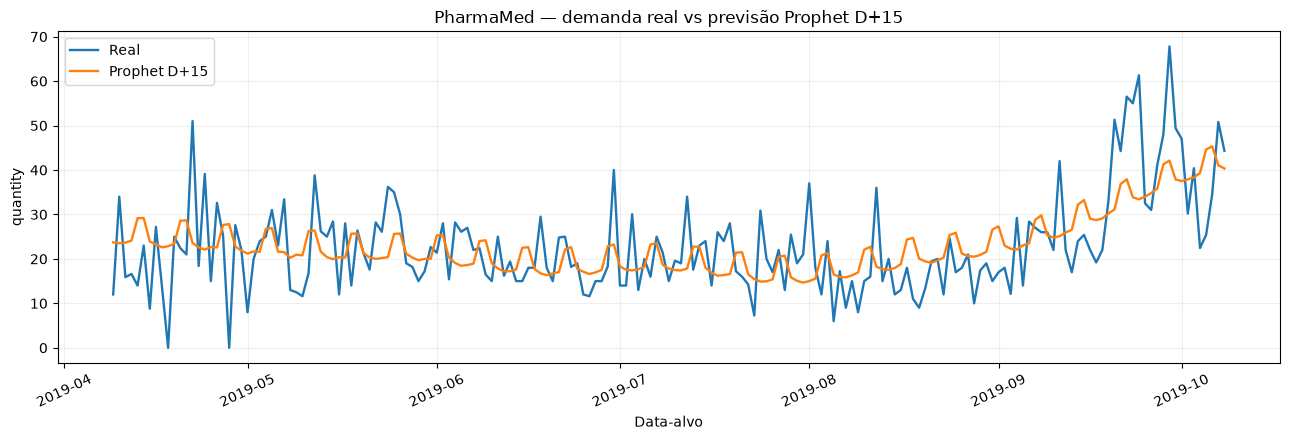

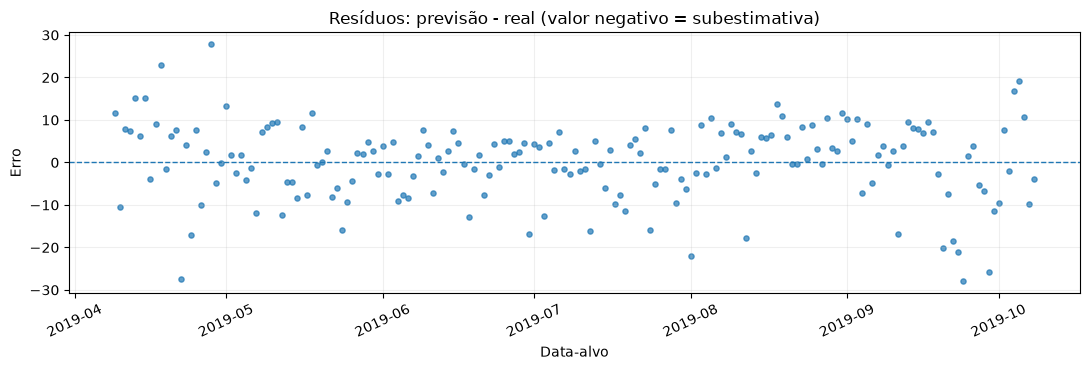

In [8]:
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(predictions_d15[DATE], predictions_d15[TARGET], label="Real", linewidth=1.7)
ax.plot(predictions_d15[DATE], predictions_d15["y_pred"], label=f"Prophet D+{HORIZON}", linewidth=1.7)
ax.set_title(f"PharmaMed — demanda real vs previsão Prophet D+{HORIZON}")
ax.set_xlabel("Data-alvo")
ax.set_ylabel(TARGET)
ax.legend()
ax.grid(alpha=0.2)
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(11, 3.8))
residuals = predictions_d15["y_pred"].to_numpy() - predictions_d15[TARGET].to_numpy()
ax.scatter(predictions_d15[DATE], residuals, s=14, alpha=0.7)
ax.axhline(0, linestyle="--", linewidth=1)
ax.set_title("Resíduos: previsão - real (valor negativo = subestimativa)")
ax.set_xlabel("Data-alvo")
ax.set_ylabel("Erro")
ax.grid(alpha=0.2)
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

## 8. Componentes do Prophet (opcional)

Com o modelo completo ajustado apenas sobre o **treino**, exiba tendência e sazonalidades aprendidas. Essa visualização ajuda na apresentação do projeto no GitHub.io/Looker Studio. Não interprete componentes como prova causal de uma tendência ou evento.

In [11]:
SHOW_COMPONENTS = False

if SHOW_COMPONENTS:
    fitted_prophet = model.get_model()  # objeto Prophet da classe, treinado em split=train
    plot_dates = pd.date_range(train_daily[DATE].min(), train_daily[DATE].max(), freq="D")
    components_forecast = fitted_prophet.predict(pd.DataFrame({"ds": plot_dates}))
    fitted_prophet.plot_components(components_forecast)
    plt.show()

## 9. Salvar artefatos para ensemble, CV, CV técnico e Looker Studio

As previsões são salvas com `forecast_origin`, `date`, `horizon_step`, `quantity` e `y_pred`, permitindo um *join* com as previsões dos outros modelos **nas mesmas origens de previsão**. As métricas do holdout final devem ser comparadas somente após o protocolo de avaliação dos quatro modelos estar alinhado.

In [10]:
output_dir = Path(MODELS_BASELINE)
output_dir.mkdir(parents=True, exist_ok=True)

pred_file = output_dir / f"prophet_predictions_fixed_h{HORIZON}.csv"
cv_file = output_dir / f"prophet_gridsearch_cv_h{HORIZON}.csv"

predictions_d15.to_csv(pred_file, index=False, encoding="utf-8-sig")
cv_results.to_csv(cv_file, index=False, encoding="utf-8-sig")
params_file = model.save_best_params(filename=f"prophet_best_params_h{HORIZON}.json")
metrics_file = model.save_metrics(metrics_d15, filename=f"prophet_metrics_fixed_h{HORIZON}.json")
model_file = model.save_model(filename=f"prophet_trained_until_split_h{HORIZON}.joblib")

print("Previsões D+H:", pred_file)
print("Resultados CV:", cv_file)
print("Melhores parâmetros:", params_file)
print("Métricas:", metrics_file)
print("Modelo treinado no split train:", model_file)
print("Nota: o modelo salvo foi ajustado ao fim do treino, não ao fim do holdout.")

Previsões D+H: D:\PROJETOS\git_repo\PharmaDemand-ml\models\baseline\prophet_predictions_fixed_h15.csv
Resultados CV: D:\PROJETOS\git_repo\PharmaDemand-ml\models\baseline\prophet_gridsearch_cv_h15.csv
Melhores parâmetros: D:\PROJETOS\git_repo\PharmaDemand-ml\models\baseline\prophet_best_params_h15.json
Métricas: D:\PROJETOS\git_repo\PharmaDemand-ml\models\baseline\prophet_metrics_fixed_h15.json
Modelo treinado no split train: D:\PROJETOS\git_repo\PharmaDemand-ml\models\baseline\prophet_trained_until_split_h15.joblib
Nota: o modelo salvo foi ajustado ao fim do treino, não ao fim do holdout.


## 10. Interpretação para inclusão no ensemble Ridge

Antes de concluir que Prophet melhora o stacking:

- Compare **D+15 com D+15**, nas mesmas datas e origens de previsão (e mesma categoria ATC).
- Compare MAE, RMSE, R², WAPE e Bias de Prophet isolado contra LightGBM, XGBoost e SARIMAX.
- Gere previsões **out-of-fold** dos modelos-base para treinar o Ridge. **Nunca** treine o Ridge diretamente nas previsões do holdout final.
- Execute o mesmo experimento Ridge **com e sem Prophet** e avalie no holdout. Um Prophet isolado fraco ainda pode ser complementar, mas isso precisa aparecer nos resultados.
- Se pretender otimizar apenas D+15, evolua o GridSearch para usar somente pontuações do passo 15 (a implementação da classe atual seleciona sobre D+1…D+15).

**Importante:** este notebook é um experimento estático de treinamento/validação. Para a fase 2 do projeto, o Streamlit/Looker Studio pode carregar os CSVs de resultados sem realizar novos treinos durante a apresentação.